## Модель прогнозирует выжил человек на титанике или нет.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import tensorflow as tf
from tensorflow.keras.layers import Dense
from tensorflow.keras import Sequential
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score
import seaborn as sns
from sklearn.metrics import confusion_matrix
from tensorflow.keras.callbacks import EarlyStopping


In [2]:
import kagglehub

In [3]:
# Download latest version
path2 = kagglehub.dataset_download("yasserh/titanic-dataset")
df2 = pd.read_csv(f'{path2}/Titanic-Dataset.csv')
df2

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S
...,...,...,...,...,...,...,...,...,...,...,...,...
886,887,0,2,"Montvila, Rev. Juozas",male,27.0,0,0,211536,13.0000,NaN,S
887,888,1,1,"Graham, Miss. Margaret Edith",female,19.0,0,0,112053,30.0000,B42,S
888,889,0,3,"Johnston, Miss. Catherine Helen ""Carrie""",female,NaN,1,2,W./C. 6607,23.4500,NaN,S
889,890,1,1,"Behr, Mr. Karl Howell",male,26.0,0,0,111369,30.0000,C148,C


In [4]:
def data_preparation(data):
    No_for_x = ['Name', 'Ticket', 'Cabin']
    drop_data = data.drop(['Name', 'Ticket', 'Cabin', 'PassengerId'], axis=1)
    # Избавление от None в данных
    drop_data = drop_data.assign(
        Age=drop_data['Age'].fillna(drop_data['Age'].median()),
        Embarked=drop_data['Embarked'].fillna(drop_data['Embarked'].mode()[0]),
        Fare=drop_data['Fare'].fillna(drop_data['Fare'].median())
    )
    prepared_data = pd.get_dummies(data=drop_data, prefix=['Sex', 'Embarked'], columns=['Sex', 'Embarked'])# one-hot
    return prepared_data

prepared_data = data_preparation(df2)

X = prepared_data.drop(['Survived'], axis=1) #2D
Y = df2['Survived'] #1D
prepared_data

,Survived,Pclass,Age,SibSp,Parch,Fare,Sex_female,Sex_male,Embarked_C,Embarked_Q,Embarked_S
0,0,3,22.0,1,0,7.2500,False,True,False,False,True
1,1,1,38.0,1,0,71.2833,True,False,True,False,False
2,1,3,26.0,0,0,7.9250,True,False,False,False,True
3,1,1,35.0,1,0,53.1000,True,False,False,False,True
4,0,3,35.0,0,0,8.0500,False,True,False,False,True
...,...,...,...,...,...,...,...,...,...,...,...
886,0,2,27.0,0,0,13.0000,False,True,False,False,True
887,1,1,19.0,0,0,30.0000,True,False,False,False,True
888,0,3,28.0,1,2,23.4500,True,False,False,False,True
889,1,1,26.0,0,0,30.0000,False,True,True,False,False


In [5]:
X_train_and_val, X_test, y_train_and_val, y_test = train_test_split(X, Y, test_size=0.2, random_state=50)# тест (20%)

X_train, X_val, y_train, y_val = train_test_split(X_train_and_val, y_train_and_val, test_size=0.25, random_state=50) #разделяем train и validation (80% * 0.75 = 60% train, 20% val)

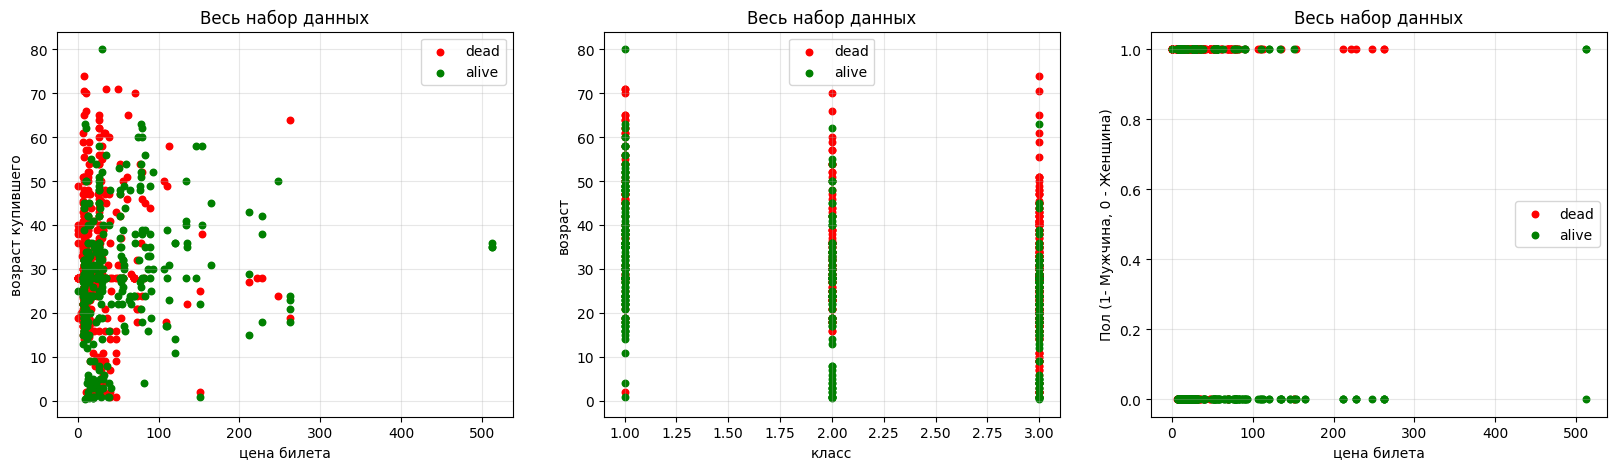

In [6]:
dead_list = ['dead', 'alive']
colors =['red', 'green']
plt.figure(figsize=(20, 5))
plt.subplot(1, 3, 1)
for i in range(2):
    mask = (Y.values == i)
    plt.scatter(X['Fare'].values[mask], X['Age'].values[mask], c=colors[i], label=dead_list[i],s=22)

plt.xlabel('цена билета')
plt.ylabel('возраст купившего')
plt.title('Весь набор данных')
plt.legend()
plt.grid(True, alpha=0.3)

plt.subplot(1, 3, 2)

for i in range(2):
    mask = (Y.values == i)
    plt.scatter(X['Pclass'].values[mask], X['Age'].values[mask], c=colors[i], label=dead_list[i],s=22)
plt.xlabel('класс')
plt.ylabel('возраст')
plt.title('Весь набор данных')
plt.legend()
plt.grid(True, alpha=0.3)

plt.subplot(1, 3, 3)

for i in range(2):
    mask = (Y.values == i)
    plt.scatter(X['Fare'].values[mask], X['Sex_male'].values[mask], c=colors[i], label=dead_list[i],s=22)
plt.xlabel('цена билета')
plt.ylabel('Пол (1- Мужчина, 0 - Женщина)')
plt.title('Весь набор данных')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

In [7]:

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

In [8]:
np.random.seed(42)
tf.random.set_seed(42)


model = Sequential([
    Dense(16, activation='relu'),
    Dense(12, activation='relu'),
    Dense(8, activation='relu'),
    Dense(4, activation='relu'),
    Dense(1, activation='sigmoid')
])
early_stop = EarlyStopping(
    monitor='val_loss',
    patience=10,
    restore_best_weights=True
)
model.compile(
    loss=tf.keras.losses.BinaryCrossentropy(),
    optimizer=tf.keras.optimizers.Adam(0.001),
    metrics=['accuracy'] #чтобы видеть accuracy по эпохам, а не только loss
)
history = model.fit(X_train_scaled, y_train, epochs=150, verbose=1, validation_data=(X_val_scaled, y_val))

Epoch 1/150
17/17 ━━━━━━━━━━━━━━━━━━━━ 2s 18ms/step - accuracy: 0.7341 - loss: 0.6824 - val_accuracy: 0.7809 - val_loss: 0.6774
Epoch 2/150
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.7547 - loss: 0.6716 - val_accuracy: 0.8090 - val_loss: 0.6635
Epoch 3/150
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.7809 - loss: 0.6568 - val_accuracy: 0.8202 - val_loss: 0.6449
Epoch 4/150
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.7846 - loss: 0.6367 - val_accuracy: 0.8315 - val_loss: 0.6217
Epoch 5/150
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.7884 - loss: 0.6111 - val_accuracy: 0.8258 - val_loss: 0.5922
Epoch 6/150
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.7865 - loss: 0.5790 - val_accuracy: 0.8202 - val_loss: 0.5566
Epoch 7/150
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.7996 - loss: 0.5417 - val_accuracy: 0.8258 - val_loss: 0.5166
Epoch 8/150
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.8146 - loss: 0.5037 - val_accuracy: 0.8258 -

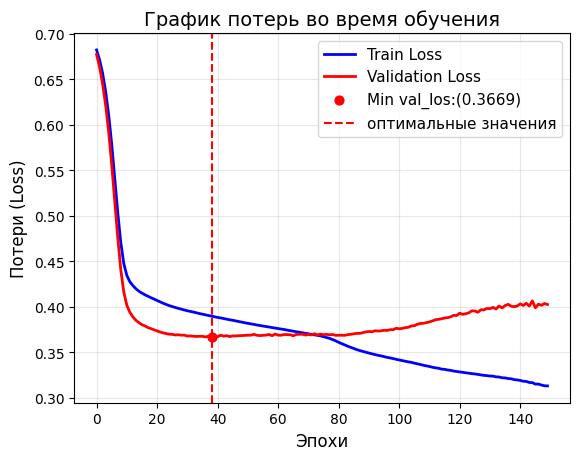

In [9]:
plt.figure()
plt.plot(history.history['loss'], label='Train Loss', color='blue', linewidth=2)# График потерь на обучении
plt.plot(history.history['val_loss'], label='Validation Loss', color='red', linewidth=2)# График потерь на валидации

epoha_minVal = history.history['val_loss'].index(min(history.history['val_loss']))
min_valLoss = min(history.history['val_loss'])
min_Loss = min(history.history['loss'])

plt.scatter(epoha_minVal, min_valLoss, color='red', s=40, zorder=5, label=f'Min val_los:({min_valLoss:.4f})')# красная точка минимума
plt.axvline(x=epoha_minVal, color='red', linestyle='--', label=f'оптимальные значения') # вертикальная линия
plt.xlabel('Эпохи', fontsize=12)
plt.ylabel('Потери (Loss)', fontsize=12)
plt.title('График потерь во время обучения', fontsize=14)
plt.legend(fontsize=11)
plt.grid(True, alpha=0.3)
plt.show()

In [10]:
pred = model.predict(X_test_scaled)
y_pred = (pred > 0.5).astype(int)# 
accuracy_score(y_test, y_pred)


6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step


0.7821229050279329

In [11]:
early_stop

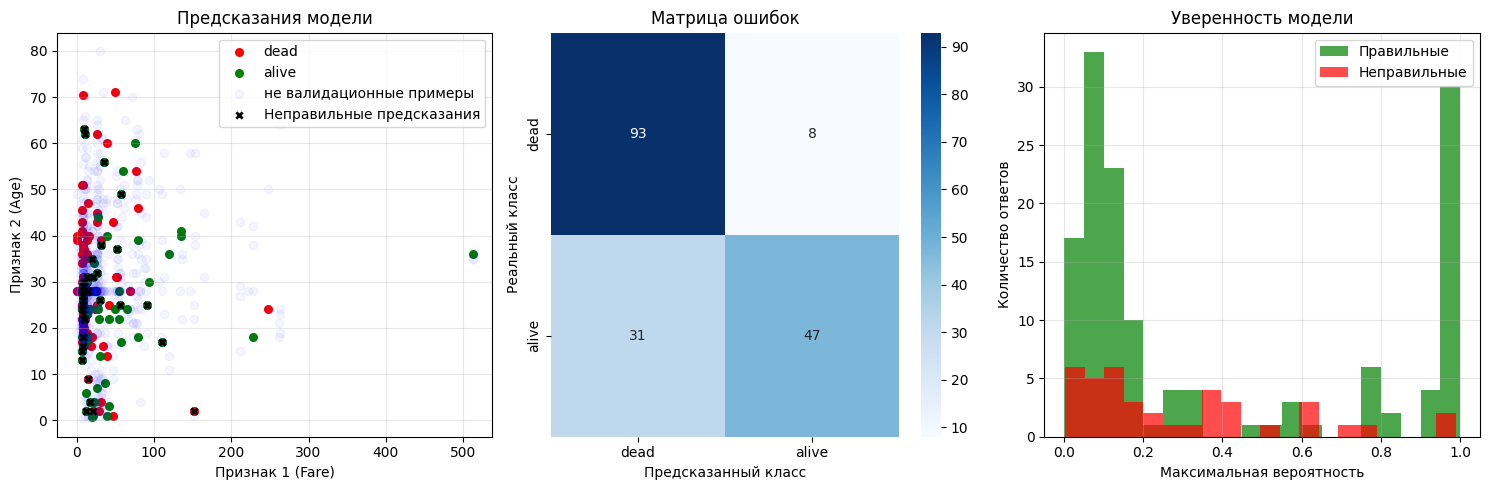

In [13]:
plt.figure(figsize=(15, 5))

# 1. Визуализация предсказаний
plt.subplot(1, 3, 1)

for i in range(2):
    mask = (y_test.values == i)
    plt.scatter(X_test['Fare'].values[mask], X_test['Age'].values[mask], c=colors[i], label=dead_list[i], s= 30)

mask1 = (Y.values == 1)
mask0 = (Y.values == 0)
plt.scatter(X['Fare'].values ,X['Age'].values, c='blue', label='не валидационные примеры', alpha=0.04)


incorrect = (y_pred.flatten() != y_test.values)
plt.scatter(X_test['Fare'].values[incorrect], X_test['Age'].values[incorrect], c='black', marker='x', s=20, linewidths=2, label='Неправильные предсказания')

plt.xlabel('Признак 1 (Fare)')
plt.ylabel('Признак 2 (Age)')
plt.title('Предсказания модели')
plt.legend()
plt.grid(True, alpha=0.3)

# 2. Матрица ошибок (Confusion Matrix)
from sklearn.metrics import confusion_matrix
import seaborn as sns

plt.subplot(1, 3, 2)
cm = confusion_matrix(y_test, y_pred.flatten())
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=dead_list, yticklabels=dead_list)

plt.xlabel('Предсказанный класс')
plt.ylabel('Реальный класс')
plt.title('Матрица ошибок')

# 3. Уверенность модели
plt.subplot(1, 3, 3)
max_probs = np.max(pred, axis=1)
correct_mask = (y_pred.flatten() == y_test.values)

plt.hist(max_probs[correct_mask], bins=20, alpha=0.7, label='Правильные', color='green')
plt.hist(max_probs[incorrect], bins=20, alpha=0.7, label='Неправильные', color='red')
plt.xlabel('Максимальная вероятность')
plt.ylabel('Количество ответов')
plt.title('Уверенность модели')
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()